# Preprocessing A — Baseline

## Idea
Careful "classic" cleaning based on the dataset documentation:
- drop columns that carry no useful information,
- fill only the **structural** missing values (NaN = the house does not have that feature),
- encode ordered categories as integers and the remaining categories with one-hot encoding,
- leave the **truly missing** values as NaN — XGBoost learns, at every split, which branch missing values should go to.

No statistics are learned from the data (no median imputation, no scaling), so the dataset can be prepared once on all rows
without leaking test information. All 2930 houses are kept: outlier removal is compared later, in `02_compare_preprocessing.ipynb`,
and applied only to the training data.

**Output:** `processed_data/A_baseline.csv`

## Steps

### 1. Load the data

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from common import CLASS_LABELS, TARGET, add_price_class, load_raw, save_processed

pd.set_option("display.max_columns", 100)

df = load_raw()
print(df.shape)
df.head()

(2930, 82)


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,Utilities,Lot Config,Land Slope,Neighborhood,Condition 1,Condition 2,Bldg Type,House Style,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Roof Style,Roof Matl,Exterior 1st,Exterior 2nd,Mas Vnr Type,Mas Vnr Area,Exter Qual,Exter Cond,Foundation,Bsmt Qual,Bsmt Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin SF 1,BsmtFin Type 2,BsmtFin SF 2,Bsmt Unf SF,Total Bsmt SF,Heating,Heating QC,Central Air,Electrical,1st Flr SF,2nd Flr SF,Low Qual Fin SF,Gr Liv Area,Bsmt Full Bath,Bsmt Half Bath,Full Bath,Half Bath,Bedroom AbvGr,Kitchen AbvGr,Kitchen Qual,TotRms AbvGrd,Functional,Fireplaces,Fireplace Qu,Garage Type,Garage Yr Blt,Garage Finish,Garage Cars,Garage Area,Garage Qual,Garage Cond,Paved Drive,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,5,1960,1960,Hip,CompShg,BrkFace,Plywood,Stone,112.0,TA,TA,CBlock,TA,Gd,Gd,BLQ,639.0,Unf,0.0,441.0,1080.0,GasA,Fa,Y,SBrkr,1656,0,0,1656,1.0,0.0,1,0,3,1,TA,7,Typ,2,Gd,Attchd,1960.0,Fin,2.0,528.0,TA,TA,P,210,62,0,0,0,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Feedr,Norm,1Fam,1Story,5,6,1961,1961,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,CBlock,TA,TA,No,Rec,468.0,LwQ,144.0,270.0,882.0,GasA,TA,Y,SBrkr,896,0,0,896,0.0,0.0,1,0,2,1,TA,5,Typ,0,NaN,Attchd,1961.0,Unf,1.0,730.0,TA,TA,Y,140,0,0,0,120,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,6,6,1958,1958,Hip,CompShg,Wd Sdng,Wd Sdng,BrkFace,108.0,TA,TA,CBlock,TA,TA,No,ALQ,923.0,Unf,0.0,406.0,1329.0,GasA,TA,Y,SBrkr,1329,0,0,1329,0.0,0.0,1,1,3,1,Gd,6,Typ,0,NaN,Attchd,1958.0,Unf,1.0,312.0,TA,TA,Y,393,36,0,0,0,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,AllPub,Corner,Gtl,NAmes,Norm,Norm,1Fam,1Story,7,5,1968,1968,Hip,CompShg,BrkFace,BrkFace,NaN,0.0,Gd,TA,CBlock,TA,TA,No,ALQ,1065.0,Unf,0.0,1045.0,2110.0,GasA,Ex,Y,SBrkr,2110,0,0,2110,1.0,0.0,2,1,3,1,Ex,8,Typ,2,TA,Attchd,1968.0,Fin,2.0,522.0,TA,TA,Y,0,0,0,0,0,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,Norm,1Fam,2Story,5,5,1997,1998,Gable,CompShg,VinylSd,VinylSd,NaN,0.0,TA,TA,PConc,Gd,TA,No,GLQ,791.0,Unf,0.0,137.0,928.0,GasA,Gd,Y,SBrkr,928,701,0,1629,0.0,0.0,2,1,3,1,TA,6,Typ,1,TA,Attchd,1997.0,Fin,2.0,482.0,TA,TA,Y,212,34,0,0,0,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900


In [2]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
pd.DataFrame({"missing": missing, "pct": (missing / len(df) * 100).round(2)})

,missing,pct
Pool QC,2917,99.56
Misc Feature,2824,96.38
Alley,2732,93.24
Fence,2358,80.48
Mas Vnr Type,1775,60.58
Fireplace Qu,1422,48.53
Lot Frontage,490,16.72
Garage Cond,159,5.43
Garage Qual,159,5.43
Garage Finish,159,5.43


### 2. Target: price classes
`SalePrice` is turned into the 6 classes from the lab requirements and then **dropped** — keeping it as a feature would give
the model the answer. The classes are imbalanced (few houses in classes 1 and 6), which is addressed in `02_compare_preprocessing.ipynb`.

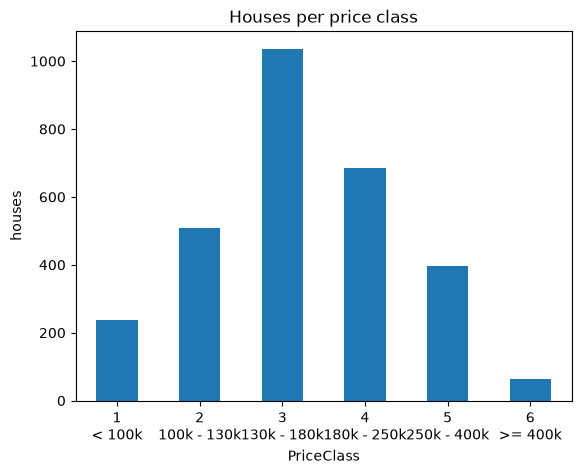

PriceClass
1     237
2     509
3    1037
4     686
5     397
6      64
Name: count, dtype: int64

In [3]:
df = add_price_class(df)

counts = df[TARGET].value_counts().sort_index()
ax = counts.plot.bar(rot=0)
ax.set_xticklabels([f"{c}\n{CLASS_LABELS[c]}" for c in counts.index])
ax.set_ylabel("houses"); ax.set_title("Houses per price class")
plt.show()
counts

### 3. Columns that are not needed
- **Identifiers**: `Order` (row number) and `PID` (parcel ID) say nothing about the price.
- **Mostly empty** (> 80% missing): `Pool QC`, `Misc Feature`, `Alley`, `Fence`. NaN means "no pool / no fence / ...", but so few
  houses have the feature that the column is almost constant.
- **Redundant**: `Garage Yr Blt` is strongly correlated with `Year Built` and undefined for houses without a garage.

In [4]:
id_cols = ["Order", "PID"]
high_missing_cols = df.columns[df.isna().mean() > 0.80].tolist()
redundant_cols = ["Garage Yr Blt"]

print("Correlation Garage Yr Blt vs Year Built:", round(df["Garage Yr Blt"].corr(df["Year Built"]), 3))
print("High-missing columns:", high_missing_cols)

df = df.drop(columns=id_cols + high_missing_cols + redundant_cols)

Correlation Garage Yr Blt vs Year Built: 0.835
High-missing columns: ['Alley', 'Pool QC', 'Fence', 'Misc Feature']


- **Near-constant**: if one value covers ≥ 99% of the rows, the column has (almost) no variance and cannot help the model.

In [5]:
dominant_share = df.apply(lambda s: s.value_counts(normalize=True, dropna=False).iloc[0])
near_constant_cols = dominant_share[dominant_share >= 0.99].index.tolist()
print(dominant_share[near_constant_cols].round(4))

df = df.drop(columns=near_constant_cols)
print(df.shape)

Street       0.9959
Utilities    0.9990
Pool Area    0.9956
dtype: float64
(2930, 72)


### 4. Missing values

According to the data documentation, most NaNs are **structural**: the house has no basement, garage, fireplace or masonry veneer.
These are filled deterministically:
- categorical → `"None"`
- related numeric (areas, counts) → `0`

The remaining NaNs are **truly missing** (e.g. `Lot Frontage`, or a house that has a basement but one descriptor is blank).
They are left as NaN for XGBoost.

In [6]:
bsmt_cat = ["Bsmt Qual", "Bsmt Cond", "Bsmt Exposure", "BsmtFin Type 1", "BsmtFin Type 2"]
bsmt_num = ["BsmtFin SF 1", "BsmtFin SF 2", "Bsmt Unf SF", "Total Bsmt SF", "Bsmt Full Bath", "Bsmt Half Bath"]
garage_cat = ["Garage Type", "Garage Finish", "Garage Qual", "Garage Cond"]
garage_num = ["Garage Cars", "Garage Area"]

# Only fill when the house really has no basement/garage; a blank descriptor of an existing one stays NaN.
no_bsmt = df["Bsmt Qual"].isna()
df.loc[no_bsmt, bsmt_cat] = "None"
df.loc[no_bsmt, bsmt_num] = df.loc[no_bsmt, bsmt_num].fillna(0)

# One house is "Detchd" but has no garage area/cars/finish -> treat it as having no garage.
no_garage = df["Garage Type"].isna() | df["Garage Area"].isna()
df.loc[no_garage, garage_cat] = "None"
df.loc[no_garage, garage_num] = df.loc[no_garage, garage_num].fillna(0)

df["Fireplace Qu"] = df["Fireplace Qu"].fillna("None")

# Masonry veneer: NaN type with area 0/NaN -> no veneer
no_mas = df["Mas Vnr Type"].isna() & (df["Mas Vnr Area"].fillna(0) == 0)
df.loc[no_mas, "Mas Vnr Type"] = "None"
df.loc[no_mas, "Mas Vnr Area"] = 0

remaining = df.isna().sum()
print("Truly missing values left for XGBoost:")
remaining[remaining > 0]

Truly missing values left for XGBoost:


Lot Frontage      490
Mas Vnr Type        7
Bsmt Exposure       3
BsmtFin Type 2      1
Electrical          1
Garage Finish       1
Garage Qual         1
Garage Cond         1
dtype: int64

### 5. Encoding

#### 5.1 Ordinal features
Quality / condition columns have a natural order (`Po < Fa < TA < Gd < Ex`), so they are mapped to integers instead of
one-hot encoded — this keeps the order and avoids many extra columns. `"None"` (feature missing) gets `0`; truly missing values stay NaN.

In [7]:
quality_map = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
ordinal_maps = {
    **{c: quality_map for c in ["Exter Qual", "Exter Cond", "Bsmt Qual", "Bsmt Cond", "Heating QC",
                                "Kitchen Qual", "Fireplace Qu", "Garage Qual", "Garage Cond"]},
    "Bsmt Exposure": {"None": 0, "No": 1, "Mn": 2, "Av": 3, "Gd": 4},
    "BsmtFin Type 1": {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "BsmtFin Type 2": {"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6},
    "Garage Finish": {"None": 0, "Unf": 1, "RFn": 2, "Fin": 3},
    "Lot Shape": {"IR3": 0, "IR2": 1, "IR1": 2, "Reg": 3},
    "Land Slope": {"Sev": 0, "Mod": 1, "Gtl": 2},
    "Paved Drive": {"N": 0, "P": 1, "Y": 2},
    "Functional": {"Sal": 0, "Sev": 1, "Maj2": 2, "Maj1": 3, "Mod": 4, "Min2": 5, "Min1": 6, "Typ": 7},
    "Central Air": {"N": 0, "Y": 1},
}
ordinal_maps = {c: m for c, m in ordinal_maps.items() if c in df.columns}

for col, mapping in ordinal_maps.items():
    unknown = set(df[col].dropna()) - set(mapping)
    assert not unknown, f"{col}: unmapped values {unknown}"
    df[col] = df[col].map(mapping)

df[list(ordinal_maps)].head()

,Exter Qual,Exter Cond,Bsmt Qual,Bsmt Cond,Heating QC,Kitchen Qual,Fireplace Qu,Garage Qual,Garage Cond,Bsmt Exposure,BsmtFin Type 1,BsmtFin Type 2,Garage Finish,Lot Shape,Land Slope,Paved Drive,Functional,Central Air
0,3,3,3,4,2,3,4,3.0,3.0,4.0,4,1.0,3.0,2,2,1,7,1
1,3,3,3,3,3,3,0,3.0,3.0,1.0,3,2.0,1.0,3,2,2,7,1
2,3,3,3,3,3,4,0,3.0,3.0,1.0,5,1.0,1.0,2,2,2,7,1
3,4,3,3,3,5,5,3,3.0,3.0,1.0,5,1.0,3.0,3,2,2,7,1
4,3,3,4,3,4,3,3,3.0,3.0,1.0,6,1.0,3.0,2,2,2,7,1


#### 5.2 Nominal features
`MS SubClass` is stored as a number but is a category code (20 = 1-story 1946+, 60 = 2-story, ...), so it is treated as text.
The remaining text columns have no order and are **one-hot encoded**. Categories with fewer than 10 houses are grouped into
`Other`, so we do not create dozens of almost-empty columns. A missing value becomes all zeros in that column's dummies.

In [8]:
MIN_CATEGORY_COUNT = 10

df["MS SubClass"] = df["MS SubClass"].astype(str)
nominal_cols = df.drop(columns=TARGET).select_dtypes(exclude="number").columns.tolist()
print(len(nominal_cols), "nominal columns:", nominal_cols)

for col in nominal_cols:
    counts = df[col].value_counts()
    rare = counts[counts < MIN_CATEGORY_COUNT].index
    df[col] = df[col].where(~df[col].isin(rare), "Other")

df = pd.get_dummies(df, columns=nominal_cols, dtype=int)
print(df.shape)

20 nominal columns: ['MS SubClass', 'MS Zoning', 'Land Contour', 'Lot Config', 'Neighborhood', 'Condition 1', 'Condition 2', 'Bldg Type', 'House Style', 'Roof Style', 'Roof Matl', 'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type', 'Foundation', 'Heating', 'Electrical', 'Garage Type', 'Sale Type', 'Sale Condition']
(2930, 202)


## Output saved

In [9]:
assert df.select_dtypes(exclude="number").empty, "all features must be numeric"
assert not df.columns.str.contains(r"[\[\]<]").any(), "XGBoost does not accept [, ] or < in feature names"

path = save_processed(df, "A_baseline")
print(f"Saved {df.shape[0]} rows x {df.shape[1] - 1} features (+ {TARGET}) to {path.name}")
print("Missing values left (handled by XGBoost):", int(df.isna().sum().sum()))

Saved 2930 rows x 201 features (+ PriceClass) to A_baseline.csv
Missing values left (handled by XGBoost): 497


**Summary:** 2930 houses, numeric features only, target `PriceClass` (1–6), truly missing values kept as NaN.
Outlier removal, the train/test split and handling class imbalance happen in `02_compare_preprocessing.ipynb`.